# Stacking Regression

A final ridge model learns how to combine a linear estimate, a forest and a boosted tree estimate. Each training prediction for the final model comes from an unseen recipe.

In [1]:
from pathlib import Path
import sys

start = Path.cwd()
for parent in (start, *start.parents):
    if (parent / "gallery" / "__init__.py").is_file():
        sys.path.insert(0, str(parent))
        break
else:
    raise RuntimeError("Open this example inside the Machine Learning collection.")

## Group-aware stacking

Each call to fit constructs fresh inner folds. Measurements of the same recipe at different ages stay together in the base models’ out-of-fold predictions.

In [2]:
import matplotlib.pyplot as plt
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import StackingRegressor, RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold
from gallery.tabular import concrete_split, regression_report


class RecipeStack(RegressorMixin, BaseEstimator):
    def fit(self, X, y):
        ingredients = X.drop(columns="age").round(1)
        group = ingredients.groupby(list(ingredients.columns), sort=False).ngroup()
        folds = list(GroupKFold(4, shuffle=True, random_state=17).split(X, y, group))
        estimators = [
            ("linear", make_pipeline(StandardScaler(), Ridge(alpha=3))),
            (
                "forest",
                RandomForestRegressor(
                    n_estimators=60, min_samples_leaf=2, random_state=17, n_jobs=1
                ),
            ),
            ("boost", HistGradientBoostingRegressor(max_iter=100, random_state=17)),
        ]
        self.model_ = StackingRegressor(
            estimators=estimators, final_estimator=Ridge(alpha=2), cv=folds
        )
        self.model_.fit(X, y)
        return self

    def predict(self, X):
        return self.model_.predict(X)

## Outer evaluation

Five outer training folds evaluate the entire stack. The recipe-grouped test partition is untouched by both levels of fitting.

Training: 824 observations across 341 recipes. Test: 206 observations.
Training folds, mean R² 0.883, MAE 4.07 MPa


                  R²  MAE (MPa)  RMSE (MPa)  Median AE (MPa)  Bias, pred − obs (MPa)
Model          0.838      4.780       6.947            3.013                  -1.995
Training mean -0.002     14.236      17.267           13.145                  -0.829
Meta-model coefficients, linear/forest/boost: [0.107 0.038 0.932]


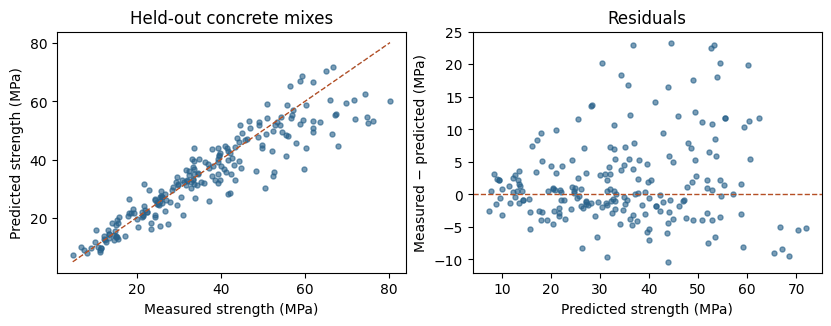

In [3]:
X, X_test, y, y_test, groups = concrete_split()
model = RecipeStack()
prediction = regression_report(model, X, X_test, y, y_test, groups)
print("Meta-model coefficients, linear/forest/boost:", model.model_.final_estimator_.coef_.round(3))
plt.show()

## Reading the result

Stacking weights can be negative and do not have to sum to one. The separate test recipes show whether the learned combination transfers.

## References

[scikit-learn, StackingRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.StackingRegressor.html)

[I-Cheng Yeh, Concrete Compressive Strength (UCI), CC BY 4.0](https://doi.org/10.24432/C5PK67)